# 03 · Diagnóstico do período crítico

**Em que fase do contrato o risco de quebra se concentra?** Duas medidas respondem a perguntas diferentes:

| Medida | Definição | Pergunta |
|---|---|---|
| **Hazard mensal** | P(default no mês *t* \| chegou ao mês *t* sem evento) | Qual o risco de um contrato que *ainda está ativo* quebrar agora? Isso orienta a **cobrança**. |
| **Distribuição dos defaults** | Fração do default acumulado (Aalen-Johansen) que acontece em cada janela | Quando as perdas *chegam* na carteira? Isso orienta o **provisionamento**. |

A diferença importa. O hazard pode ficar alto até o fim do contrato, mas, como a carteira encolhe com os pré-pagamentos, a maior parte das perdas chega antes.

**Regra da janela crítica:** é o maior trecho contínuo em torno do pico em que o hazard (média móvel de 3 meses) fica acima de 90% do pico. O último mês do contrato fica de fora, porque concentra contratos que atrasaram, pagaram a última parcela depois do vencimento e só então foram baixados (o tempo deles foi truncado no prazo, ver notebook 01).

Todos os números usam a observação até nov/2018 (censura administrativa, ver notebook 01). Sem esse corte, o hazard das safras de 2017–2018 aparecia artificialmente baixo, porque os defaults mais recentes ainda não tinham virado charge-off.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from time_to_default.features import PROCESSED_PATH
from time_to_default.plotting import (BLUE, GRAY, LIGHT_GRAY, ORANGE, SERIES, ordinal_colors,
                                      percent_axis, savefig, set_style)
from time_to_default.reporting import update_metrics
from time_to_default.survival import (critical_window, default_share_by_window, life_table,
                                      life_tables_by, smoothed_hazard)

set_style()
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

data = pd.read_parquet(PROCESSED_PATH)
TERMS = (36, 60)
by_term = {t: data[data["term_months"] == t] for t in TERMS}
overall = {t: life_table(s["duration"], s["event"]) for t, s in by_term.items()}

## 1. Hazard mensal de default

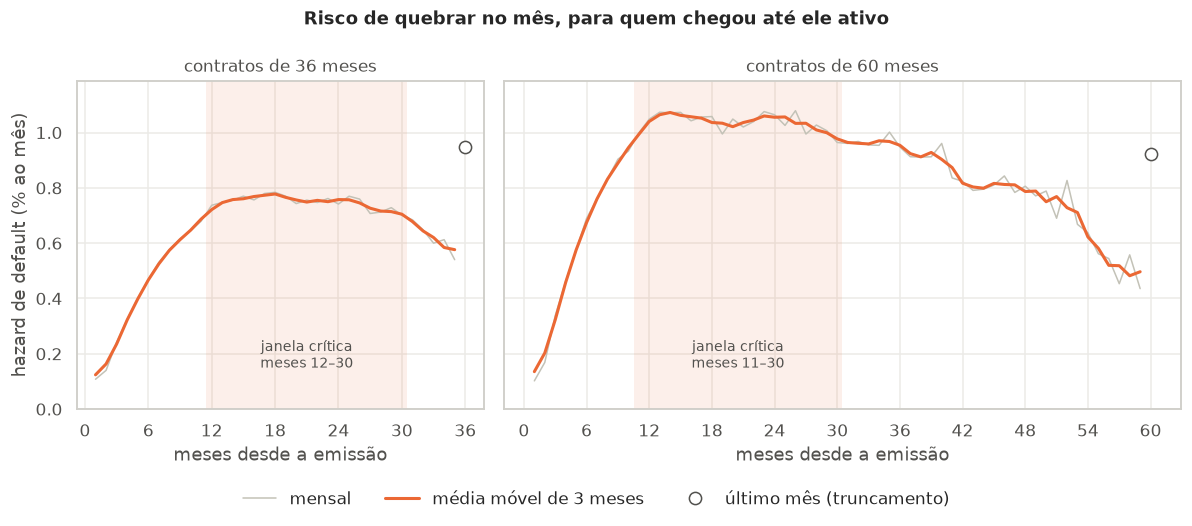

,mês do pico,hazard no pico (% a.m.),início,fim
36,18.000,0.778,12.000,30.000
60,14.000,1.072,11.000,30.000


In [2]:
windows = {t: critical_window(smoothed_hazard(tab)) for t, tab in overall.items()}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True, gridspec_kw={"width_ratios": TERMS})
for ax, (term, tab) in zip(axes, overall.items()):
    raw = 100 * tab["hazard_default"]
    w = windows[term]
    ax.axvspan(w["start"] - 0.5, w["end"] + 0.5, color=ORANGE, alpha=0.10, lw=0)
    ax.plot(raw.index[:-1], raw.iloc[:-1], color=LIGHT_GRAY, lw=1, label="mensal")
    ax.plot(smoothed_hazard(tab), color=ORANGE, label="média móvel de 3 meses")
    ax.plot(term, raw.iloc[-1], "o", ms=8, mfc="white", mec=GRAY, label="último mês (truncamento)")
    ax.annotate(f"janela crítica\nmeses {w['start']}–{w['end']}", ((w["start"] + w["end"]) / 2, 0.15),
                ha="center", fontsize=9, color=GRAY)
    ax.set_title(f"contratos de {term} meses", fontsize=11, fontweight="normal", color=GRAY)
    ax.set_xticks(range(0, term + 1, 6))
    ax.set_xlabel("meses desde a emissão")
axes[0].set_ylim(0, 1.1 * max(100 * tab["hazard_default"].max() for tab in overall.values()))
axes[0].set_ylabel("hazard de default (% ao mês)")
fig.suptitle("Risco de quebrar no mês, para quem chegou até ele ativo", fontweight="bold", fontsize=12)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, ncol=3, loc="lower center", bbox_to_anchor=(0.5, -0.08), frameon=False)
fig.tight_layout()
savefig(fig, "hazard_by_term")
plt.show()

pd.DataFrame(windows).T.rename(columns={
    "peak_month": "mês do pico", "peak_hazard": "hazard no pico (% a.m.)", "start": "início", "end": "fim"})

In [3]:
checkpoints = {36: [1, 3, 6, 9, 12, 18, 24, 30, 35], 60: [1, 3, 6, 9, 12, 18, 24, 36, 48, 59]}
pd.DataFrame({f"{t}m": smoothed_hazard(tab).loc[checkpoints[t]] for t, tab in overall.items()}).rename_axis("mês")

,36m,60m
mês,,
1,0.124,0.135
3,0.235,0.323
6,0.467,0.674
9,0.612,0.889
12,0.721,1.040
18,0.778,1.036
24,0.758,1.055
30,0.705,NaN
35,0.576,NaN


## 2. Quando as perdas chegam

A fração de todos os defaults (Aalen-Johansen) que acontece em cada janela já desconta os contratos que saíram por pré-pagamento ou censura.

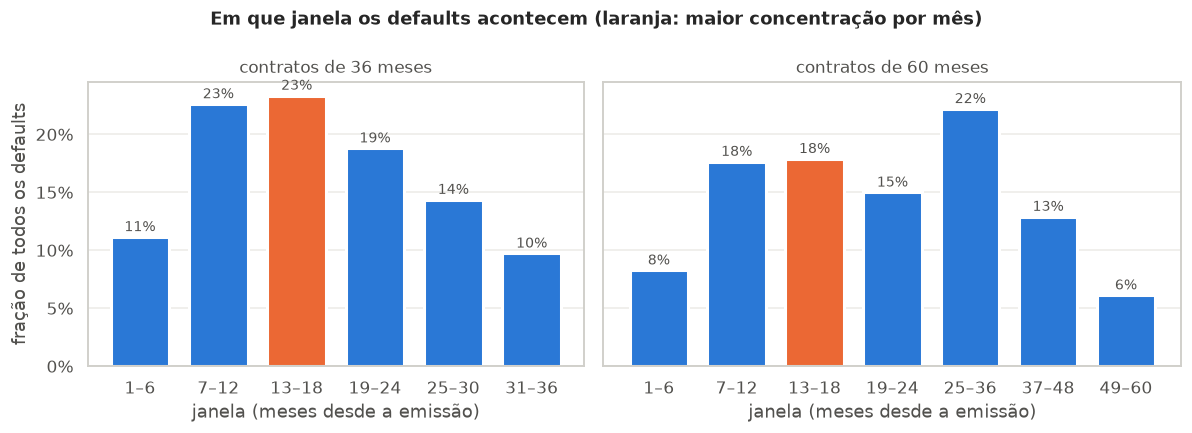

,36m,60m
ano do contrato,,
13–24,0.421,0.329
1–12,0.338,0.259
25–36,0.241,0.222
37–48,NaN,0.129
49–60,NaN,0.061


In [4]:
BINS = {36: [0, 6, 12, 18, 24, 30, 36], 60: [0, 6, 12, 18, 24, 36, 48, 60]}
shares = {t: default_share_by_window(tab, BINS[t]) for t, tab in overall.items()}

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True, gridspec_kw={"width_ratios": [6, 7]})
for ax, (term, s) in zip(axes, shares.items()):
    per_month = s / pd.Series([b - a for a, b in zip(BINS[term][:-1], BINS[term][1:])], index=s.index)
    top = per_month.idxmax()
    colors = [ORANGE if k == top else BLUE for k in s.index]
    ax.bar(s.index.astype(str), s.values, color=colors, width=0.75, edgecolor="white", linewidth=2)
    for x, v in enumerate(s.values):
        ax.text(x, v + 0.005, f"{100 * v:.0f}%", ha="center", fontsize=9, color=GRAY)
    ax.set_title(f"contratos de {term} meses", fontsize=11, fontweight="normal", color=GRAY)
    ax.set_xlabel("janela (meses desde a emissão)")
    ax.grid(axis="x", visible=False)
    percent_axis(ax)
axes[0].set_ylabel("fração de todos os defaults")
fig.suptitle("Em que janela os defaults acontecem (laranja: maior concentração por mês)",
             fontweight="bold", fontsize=12)
fig.tight_layout()
savefig(fig, "default_share_by_window")
plt.show()

year_split = pd.DataFrame({
    f"{t}m": default_share_by_window(tab, list(range(0, t + 1, 12))) for t, tab in overall.items()
}).rename_axis("ano do contrato")
year_split

## 3. Quanto pior o grade, mais cedo a quebra

Nos contratos de 36 meses, o formato do hazard muda com o grade. Para comparar só o *formato*, cada curva abaixo é dividida pelo próprio pico, porque os níveis variam mais de dez vezes entre A e G (ver a tabela).

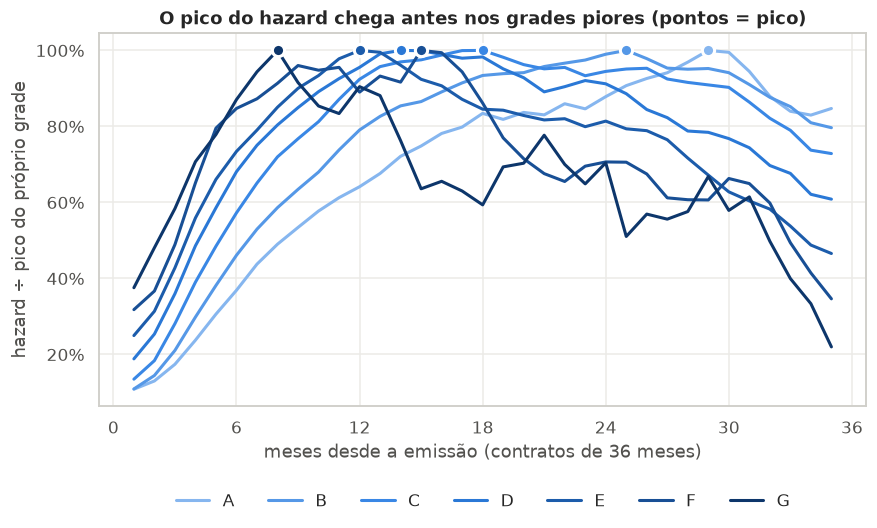

,mês do pico,hazard no pico (% a.m.),início da janela,fim da janela,defaults no 1º ano
A,29.000,0.332,25.000,31.000,0.257
B,25.000,0.664,17.000,31.000,0.287
C,18.000,1.060,12.000,30.000,0.339
D,14.000,1.482,11.000,20.000,0.396
E,12.000,1.974,9.000,16.000,0.455
F,15.000,2.423,13.000,17.000,0.503
G,8.000,3.689,7.000,9.000,0.587


In [5]:
grade_tabs = life_tables_by(by_term[36], "grade")
grade_haz = {g: smoothed_hazard(tab) for g, tab in grade_tabs.items()}
grade_windows = pd.DataFrame({g: critical_window(h) for g, h in grade_haz.items()}).T
grade_windows["share_first_year"] = [
    default_share_by_window(tab, [0, 12, 36]).iloc[0] for tab in grade_tabs.values()
]

fig, ax = plt.subplots(figsize=(9, 4.4))
for (g, h), color in zip(grade_haz.items(), ordinal_colors(7)):
    ax.plot(h.index, h / h.max(), color=color, label=g)
    peak = int(h.idxmax())
    ax.plot(peak, 1.0, "o", color=color, ms=8, mec="white", mew=2)
ax.set_xticks(range(0, 37, 6))
ax.set_xlabel("meses desde a emissão (contratos de 36 meses)")
ax.set_ylabel("hazard ÷ pico do próprio grade")
ax.set_title("O pico do hazard chega antes nos grades piores (pontos = pico)")
percent_axis(ax)
ax.legend(ncol=7, loc="lower center", bbox_to_anchor=(0.5, -0.32), frameon=False)
savefig(fig, "hazard_shape_by_grade")
plt.show()

grade_windows.rename(columns={
    "peak_month": "mês do pico", "peak_hazard": "hazard no pico (% a.m.)", "start": "início da janela",
    "end": "fim da janela", "share_first_year": "defaults no 1º ano"})

## 4. Estabilidade: o formato muda entre safras?

Se a curva de hazard mudar muito entre safras, uma curva única da carteira fica enganosa, e o modelo validado no passado pode não valer para as safras novas.

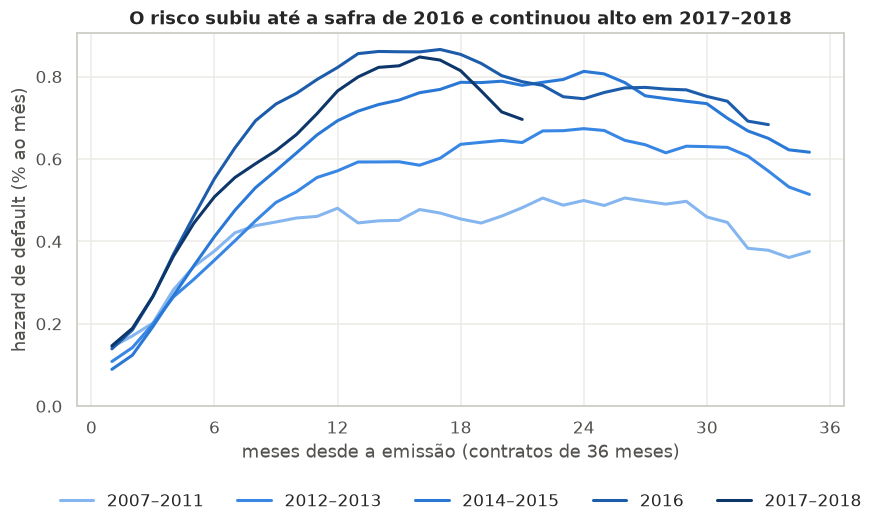

,contratos,hazard mês 6,hazard mês 12,hazard mês 18,hazard mês 24,último mês observado
2007–2011,"28,996.000",0.377,0.480,0.454,0.499,35.000
2012–2013,"143,817.000",0.354,0.571,0.636,0.674,35.000
2014–2015,"445,502.000",0.412,0.693,0.786,0.813,35.000
2016,"318,187.000",0.552,0.822,0.854,0.746,33.000
2017–2018,"550,100.000",0.508,0.765,0.814,NaN,21.000


In [6]:
s36 = by_term[36].assign(cohort=pd.cut(by_term[36]["vintage"], [2006, 2011, 2013, 2015, 2016, 2018],
                                         labels=["2007–2011", "2012–2013", "2014–2015", "2016", "2017–2018"]))
cohort_haz = {c: smoothed_hazard(tab) for c, tab in life_tables_by(s36, "cohort").items()}

fig, ax = plt.subplots(figsize=(9, 4.4))
for (c, h), color in zip(cohort_haz.items(), ordinal_colors(5)):
    ax.plot(h.index, h, color=color, label=c)
ax.set_xticks(range(0, 37, 6))
ax.set_xlabel("meses desde a emissão (contratos de 36 meses)")
ax.set_ylabel("hazard de default (% ao mês)")
ax.set_title("O risco subiu até a safra de 2016 e continuou alto em 2017–2018")
ax.set_ylim(0, None)
ax.legend(ncol=5, loc="lower center", bbox_to_anchor=(0.5, -0.32), frameon=False)
savefig(fig, "hazard_by_cohort")
plt.show()

cohort_table = pd.DataFrame({
    c: {"contratos": int(life_tables_by(s36, "cohort")[c]["at_risk"].iloc[0]),
        "hazard mês 6": h.get(6), "hazard mês 12": h.get(12), "hazard mês 18": h.get(18),
        "hazard mês 24": h.get(24), "último mês observado": int(h.index.max())}
    for c, h in cohort_haz.items()
}).T
cohort_table

## 5. Prazo: o efeito é constante no tempo?

A razão entre os hazards de 60 e 36 meses, mês a mês, é uma prévia da hipótese central do Cox: se a razão for estável, o prazo entra como covariável. Se oscilar, entra como estrato.

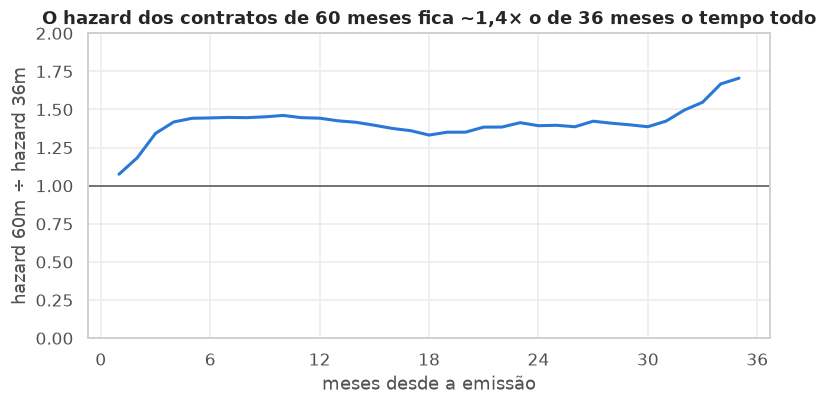

,razão
month,
3,1.340
6,1.440
12,1.440
18,1.330
24,1.390
30,1.390
34,1.670


In [7]:
ratio = (overall[60]["hazard_default"] / overall[36]["hazard_default"]).loc[1:35]
ratio_smooth = ratio.rolling(3, center=True, min_periods=1).mean()

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(ratio_smooth.index, ratio_smooth, color=BLUE)
ax.axhline(1, color=GRAY, lw=1)
ax.set_ylim(0, 2)
ax.set_xticks(range(0, 37, 6))
ax.set_xlabel("meses desde a emissão")
ax.set_ylabel("hazard 60m ÷ hazard 36m")
ax.set_title("O hazard dos contratos de 60 meses fica ~1,4× o de 36 meses o tempo todo")
savefig(fig, "hazard_ratio_term")
plt.show()
ratio_smooth.loc[[3, 6, 12, 18, 24, 30, 34]].round(2).to_frame("razão")

## Diagnóstico

Os números citados aqui saem das tabelas acima (e de `reports/metrics.json`).

1. **O risco não chega de uma vez, ele acelera no primeiro ano.** Nos contratos de 36 meses, o hazard sai de 0,12% ao mês no 1º mês para 0,72% no 12º. Do 12º ao 30º mês ele fica num **platô**, que é a janela crítica, com pico de 0,78% no 18º mês. Depois cai, porque quem sobreviveu até ali é cada vez mais o bom pagador. Nos contratos de 60 meses o formato é o mesmo (janela do 11º ao 30º mês), num nível cerca de 40% acima.
2. **A pergunta "entre o 6º e o 12º mês?" tem duas respostas.** Até o 12º mês o risco **cresce** (6 vezes entre o 1º e o 12º mês), e do 12º ao 30º ele **fica no máximo**. Em perdas, a maior concentração está entre o **7º e o 18º mês**, que juntam 46% de todos os defaults dos contratos de 36 meses.
3. **O grade muda o *quando*, não só o *quanto*.** O pico vem no 8º mês no grade G, perto do 12º–15º nos grades E e F, no 18º no C e só no 29º no A. A fração dos defaults que acontece no 1º ano vai de 26% (A) a 59% (G). Para a cobrança, isso significa régua preventiva desde os primeiros meses nos grades piores e monitoramento mais tardio nos melhores.
4. **O risco subiu entre as safras.** O hazard no 12º mês passou de 0,48% (2007–2011) para 0,82% (2016) e continuou alto em 2017–2018 (0,77%), subindo mais cedo. Isso é um alerta para o modelo: um Cox ajustado nas safras antigas tende a **subestimar** o risco das novas. A Parte 5 testa isso com validação fora do tempo.
5. **Implicação para o Cox:** a razão de hazards 60m/36m é estável (cerca de 1,4×), então o prazo pode entrar como covariável. Já o grade muda o *formato* do hazard, e é provável que viole a hipótese de riscos proporcionais. O notebook 04 testa isso formalmente (resíduos de Schoenfeld).

In [8]:
update_metrics("critical_period", {
    f"term_{t}": {
        "peak_month": windows[t]["peak_month"],
        "peak_hazard_pct_month": round(windows[t]["peak_hazard"], 3),
        "critical_window": [windows[t]["start"], windows[t]["end"]],
        "hazard_month_1": round(float(smoothed_hazard(overall[t]).loc[1]), 3),
        "hazard_month_6": round(float(smoothed_hazard(overall[t]).loc[6]), 3),
        "hazard_month_12": round(float(smoothed_hazard(overall[t]).loc[12]), 3),
        "default_share_by_window": shares[t].round(4).to_dict(),
        "default_share_by_year": year_split[f"{t}m"].dropna().round(4).to_dict(),
    }
    for t in TERMS
} | {
    "grade_36m_peak_month": grade_windows["peak_month"].astype(int).to_dict(),
    "grade_36m_share_first_year": grade_windows["share_first_year"].astype(float).round(4).to_dict(),
    "hazard_ratio_60_vs_36_median": round(float(ratio_smooth.median()), 3),
})

{'data': {'raw_loans': 2260668,
  'loans': 2064692,
  'snapshot': '2019-03',
  'observation_end': '2018-11',
  'funnel': [{'etapa': 'base bruta', 'contratos': 2260668, 'removidos': 0},
   {'etapa': 'dentro da política de crédito',
    'contratos': 2257919,
    'removidos': 2749},
   {'etapa': 'pedido individual', 'contratos': 2137209, 'removidos': 120710},
   {'etapa': 'moradia própria, financiada ou aluguel',
    'contratos': 2136024,
    'removidos': 1185},
   {'etapa': 'renda anual positiva', 'contratos': 2136024, 'removidos': 0},
   {'etapa': 'emitido antes do fim da observação',
    'contratos': 2064692,
    'removidos': 71332}],
  'event_share': {'censurado': 0.5047,
   'pré-pagamento': 0.3715,
   'default': 0.1239},
  'term_36_share': 0.72},
 'kaplan_meier': {'term_36': {'cif_default_12m': 0.0487,
   'cif_default_term': 0.1444,
   'naive_km_default_term': 0.206,
   'cif_prepay_term': 0.5623},
  'term_60': {'cif_default_12m': 0.07,
   'cif_default_term': 0.27,
   'naive_km_defaul